In [1]:
import os 
import gym 
import numpy as np
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.env_checker import check_env
from stable_baselines3 import PPO
import os
import random
import ray

/home/domenico/Desktop/bioai/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2025-08-26 16:16:12,694	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


In [2]:
import flwr as fl
from flwr.common import Metrics
from logging import INFO, log, DEBUG

from flwr.common import (
    EvaluateIns,
    EvaluateRes,
    FitIns,
    FitRes,
    MetricsAggregationFn,
    NDArrays,
    Parameters,
    Scalar,
    ndarrays_to_parameters,
    parameters_to_ndarrays,
)

from flwr.server.strategy.aggregate import aggregate

import torch
from typing import Dict, List, Optional, Tuple
from torch.utils.tensorboard import SummaryWriter

import multiprocessing


from model import Net, train, test, get_parameters, set_parameters
from HierFL import HierFL
from client import FlowerClient
from strategy import FedAvgCustom
from load_datasets import load_datasets
from utils import generate_random_sizes



/home/domenico/Desktop/bioai/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2025-06-17 10:28:42,014	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


# Create Environment

In [3]:
import gym 
from gym import Env
from gym.spaces import Discrete, Box,MultiDiscrete,Dict,Tuple

In [93]:
#Box(low=0.0, high=1.0, shape=(7,), dtype=np.float32).sample()
#MultiDiscrete([70,18]).sample()

K1 va da 5 a 75 
K2 va da 2 a 20

In [ ]:
class OptHierFLEnv(Env):

    def __init__(self, env_name: str,max_round: int = 10):
        '''Inizializzazione dell'ambiente di ottimizzazione per HierFL.
        
        -Args:
            env_name: nome dell'ambiente (per esempio "HierFL-v0")
            max_round: numero massimo di round di simulazione (default: 10)


        -Attribites:
            action_space: spazio delle azioni, MultiDiscrete con 70 valori [5,75] per k1 e 18 [2,20] per k2
            observation_space: spazio delle osservazioni, Box con 6 valori normalizzati tra 0 e 1
                1) accuracy [0,1]
                2) training time [0,2000]
                3) computation energy [0,10]
                4) communication energy [0,500]
                5) total energy [0,510]
                6) communications [0,5000] 
                7) accuracy increase [0,1]
                8) communication energy increase [0,1]

            time_min, time_max: intervallo per il tempo di addestramento
            computation_energy_min, computation_energy_max: intervallo per l'energia di calcolo
            communication_energy_min, communication_energy_max: intervallo per l'energia di comunicazione
            total_energy_min, total_energy_max: intervallo per l'energia totale
            comms_min, comms_max: intervallo per le comunicazioni

            n_rounds: numero di round di simulazione
            current_round: round corrente della simulazione
            state: stato iniziale dell'ambiente (normalizzato)

            last_accuracy: ultima accuratezza ottenuta (per vedere miglioramenti)
            last_communication_energy: ultima energia di comunicazione ottenuta (per vedere miglioramenti)


        
        '''
        # Inizializza l'ambiente di ottimizzazione per HierFL
        #alternative MultiDiscrete([3,3])  #up = 0, down = 1, hold = 2
        self.action_space=MultiDiscrete([70,18])
        self.observation_space=Box(low=0.0, high=1.0, shape=(8,), dtype=np.float32)

        
        # Range 
        self.time_min, self.time_max = 0, 2000
        self.computation_energy_min, self.computation_energy_max = 0, 10 
        self.communication_energy_min, self.communication_energy_max = 0, 500
        self.total_energy_min, self.total_energy_max = 0, 510
        self.comms_min, self.comms_max = 0, 5000

        #simulazione di n round 
        self.n_rounds = max_round  
        self.current_round = 0 
       
        #stato iniziale dell'ambiente
        self.state=self.get_initial_state() 
        
        #self.last_total_energy = 0.0
        self.last_accuracy = 0.0
        self.last_communication_energy = 0.0
        

    def get_initial_state(self):
        '''Restituisce lo stato iniziale dell'ambiente.

        Returns:
            state (np.ndarray): array normalizzato che rappresenta lo stato iniziale 
            dell'ambiente. Contiene 8 valori:
                - 0: accuratezza iniziale (acc)
                - self.time_max: tempo massimo di training
                - self.computation_energy_max: energia computazionale massima
                - self.communication_energy_max: energia di comunicazione massima
                - self.total_energy_max: energia totale massima
                - self.comms_max: numero massimo di comunicazioni
                - 0: incremento iniziale di accuratezza
                - 0: incremento iniziale dell'energia di comunicazione
        '''
        return np.array([
            0,  # acc
            self.time_max,  # training_time
            self.computation_energy_max,  # computation_energy
            self.communication_energy_max,  # communication_energy
            self.total_energy_max,  # total_energy
            self.comms_max,  # communications
            0,  # accuracy increase
            0   # communication energy increase
        ], dtype=np.float32)

    
    def normalize(self, value, min_value, max_value):
        ''' Funzione per normalizzare un valore in un range [0, 1].
        -Args:
            value: valore da normalizzare
            min_value: valore minimo del range
            max_value: valore massimo del range
        -Returns:
            value: valore normalizzato in un range [0, 1]
        ''' 
        if max_value - min_value == 0:
            return 0.0
        return (value - min_value) / (max_value - min_value)
    


    def decode_action(self, action):
        '''  Funzione per decodificare l'azione in k1 e k2. 
        -Args:
            action: azione dell'agente con parametri k1 in un range [0, 70] e k2 in un range [0, 18]
        -Returns:
            k1: primo iperparametro, in un range [5, 75]
            k2: secondo iperparametro, in un range [2, 20]
        '''
        k1=action[0]+5 #k1 in the range [5, 75]
        k2=action[1]+2 #k2 in the range [2, 20]
        return k1, k2


    def step(self,action):
        '''
        La funzione step(action):
        Riceve un'azione dall'agente (qui: una coppia di iperparametri k1, k2)
        Esegue la simulazione con quell'azione (HierFL round)
        Calcola la reward
        Aggiorna lo stato

        Restituisce:
        il nuovo stato (osservazione)
        la reward 
        il flag done 
        un dizionario info 

        -Args:
            action: azione dell'agente, una coppia di iperparametri k1 e k2
        -Returns:
            state: nuovo stato dell'ambiente, un array normalizzato con 7 valori
            reward: ricompensa calcolata in base ai risultati della simulazione
            done: flag che indica se la simulazione è terminata (tutti i round completati)
            info: dizionario con informazioni aggiuntive, come i valori di k1 e

        '''

        #recupero k1 e k2 
        k1, k2 = self.decode_action(action)


        results = self.run_HierFL(k1, k2)

        accuracy = results['accuracy']
        accuracy_improvement = accuracy - self.last_accuracy

        communication_energy = results['comm_energy']
        communication_energy_improvements =self.last_communication_energy-communication_energy

        self.state= state = np.array([
            self.normalize(results['loss'], 0, 2),  # ipotesi: loss tra 0 e 2
            self.normalize(accuracy, 0, 1),
            self.normalize(results['training_time'], self.time_min, self.time_max),
            self.normalize(results['computation_energy'], self.energy_min, self.energy_max),
            self.normalize(results['communication_energy'], self.energy_min, self.energy_max),
            self.normalize(results['total_energy'], self.energy_min, self.energy_max),
            self.normalize(results['communications'], self.comms_min, self.comms_max),
            self.normalize(accuracy_improvement, 0, 1),  # incremento di accuratezza
            self.normalize(communication_energy_improvements,  self.energy_min, self.energy_max)  # incremento di energia di comunicazione
        ], dtype=np.float32)


        #Compute the reward
        reward = self.compute_reward(results)

        done = self.current_round >= self.n_rounds

        info = {'k1': k1, 'k2': k2, 'round': self.current_round}
        self.current_round += 1

        # Aggiorno l'ultima accuratezza e l'ultima energia di comunicazione
        self.last_accuracy = accuracy
        self.last_communication_energy = communication_energy

        return self.state, reward, done, info

    
    def render(self):
        pass


    def reset(self):
        '''Reset dell'ambiente per un nuovo episodio di ottimizzazione.'''
        self.state = self.get_initial_state()
        self.current_round = 0
        self.last_accuracy = 0.0
        self.last_communication_energy = 0.0
        return self.state
    

    def compute_reward(self, results):
        '''Calcola la ricompensa in base ai risultati della simulazione.'''

        reward = 0.0

        # Penalizza se il tempo di addestramento supera il massimo
        if results["training_time"] > 1200:
            reward -= 1.0
            return reward

         # Normalizzazioni
        accuracy = results['accuracy']
        norm_training_time = self.normalize(results['training_time'], self.time_min, self.time_max)
        norm_comp_energy = self.normalize(results['computation_energy'], self.computation_energy_min, self.computation_energy_max)
        norm_comm_energy = self.normalize(results['communication_energy'], self.communication_energy_min, self.communication_energy_max)
        norm_total_energy = self.normalize(results['total_energy'], self.total_energy_min, self.total_energy_max)
        norm_comms = self.normalize(results['communications'], self.comms_min, self.comms_max)

        accuracy_improvement = accuracy - self.last_accuracy
        comm_energy_improvement = self.last_communication_energy - results['communication_energy']

        # Componenti della reward
        reward = 0.0
        reward += 0.5 * accuracy  # Ricompensa principale per l'accuratezza
        reward += 0.2 * max(accuracy_improvement, 0)  # Ricompensa bonus se l'accuratezza migliora
        reward += 0.1 * max(comm_energy_improvement, 0)  # Ricompensa se si riduce energia di comunicazione
        reward -= 0.1 * norm_training_time  # Penalizza tempo
        reward -= 0.05 * norm_total_energy  # Penalizza energia totale
        reward -= 0.05 * norm_comms  # Penalizza troppe comunicazioni

        # Clipping del reward in un range ragionevole
        reward = max(min(reward, 1.0), -1.0)

        return reward
       


            
    def run_HierFL(self, k1, k2):
        '''Esegue un round di HierFL con i parametri k1 e k2.gestendo il ciclo di vita di Ray.'''
        print(f"Running HierFL with k1={k1}, k2={k2}")

        # Inizializza Ray. ignora l'errore se è già inizializzato (utile per il primo avvio)
        ray.init(ignore_reinit_error=True, log_to_driver=False)

        try: 
            args = {
            'EXPERIMENT': 11,
            'SEED': 3,
            'DATASET': "cifar10",
            'DATA_DISTRIBUTION': "IID",
            'TYPE_DISTRIBUTION': "dirichlet",
            'NUM_CLIENTS': 30, # 30
            'LOCAL_ITERATIONS': k1, # k1
            'EDGE_AGGREGATIONS': k2, # k2 10
            'GLOBAL_ROUNDS': 25, #25
            'TRAIN_PHASES': 5,
            #'NUM_EDGES_SERVERS': 5,
            'ACTUAL_GLOBAL_ROUND': 0,
            'ACTUAL_EDGE_ROUND': 0,
            'EDGE_CLIENTS': 10,
            'CLIENT_FRACTION': 0.7,
            'EVALUATE_FRACTION': 0.7,
            'MIN_FIT_CLIENT': 6,
            'MIN_EVALUATE_CLIENT': 6,
            'MIN_AVAILABLE_CLIENT': 8,
            'BATCH_SIZE': 20,
            'LEARNING_RATE': 0.01,
            'EXPONENTIAL_DECAY_RATE': 0.995
            }

            # MAKE EXPERIMENTS REPEATABLE
            torch.manual_seed(args['SEED'])
            np.random.seed(args['SEED'])

            trainloaders, valloaders, testloader = load_datasets(args)

            args['DEVICE'] = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # Try "cuda" to train on GPU
            print(f"Training on {args['DEVICE']} using PyTorch {torch.__version__} and Flower {fl.__version__}")

            # Specify the resources each of your clients need. 
            # By default, each client will be allocated 1x CPU and 0x GPUs
            client_resources = {"num_cpus": 1, "num_gpus": 0.0}
            args['client_resources'] = client_resources
            if args['DEVICE'].type == "cuda":
                # here we are assigning an entire GPU for each client.
                args['client_resources'] = {"num_cpus": 1, "num_gpus": 1}

            # Leaf directory
            directory = "Experiment_" + str(args['EXPERIMENT'])
            # Parent Directories
            parent_dir = "Experiments_Reinforcement"
            # Path
            dir_path = os.path.join(parent_dir, directory)
            args['dir_path'] = dir_path
            # Create the directory 'ihritik'
            try:
                os.makedirs(dir_path, exist_ok=True)
                print("Directory '%s' created successfully" % directory)
            except OSError as error:
                print("Directory '%s' can not be created")
            

            results=HierFL(args, trainloaders, valloaders, testloader)
        
        finally:
            # FONDAMENTALE: spegni Ray, qualunque cosa accada
            print("Spegnimento di Ray in corso...")
            ray.shutdown()
            print("Ray spento.")
        
        return results

   

## Test ENV

In [18]:
env= OptHierFLEnv(env_name="HierFL-v0", max_round=5)

In [19]:
env.observation_space.sample()  


array([0.46165663, 0.95836294, 0.73560846, 0.37273106, 0.62190056,
       0.67764604, 0.64922404, 0.2945572 ], dtype=float32)

In [20]:
env.action_space.sample()

array([48,  6])

In [21]:
env.reset()

array([   0., 2000.,   10.,  500.,  510., 5000.,    0.,    0.],
      dtype=float32)

In [ ]:
episodes = 5
for episode in range(1, episodes+1):
    state = env.reset()
    done = False
    score = 0 
    
    while not done:
        env.render()
        action = env.action_space.sample()
        n_state, reward, done, info = env.step(action)
        score+=reward
    print('Episode:{} Score:{}'.format(episode, score))
env.close()

# model free optimization
Basandomi sulle info sull'action space (non obs space). MultiDiscrete Posso usare A2C o PPO (cofronto(?))


# Analisi correlazione lineare

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
filename = "pre_analisys.csv"

In [5]:
df=pd.read_csv(filename)
df.head(2)

,Loss,Accuracy,Training time (s),Energy Computation,Energy Communication,Total Energy,Number of communications
0,0.003801,0.1570,2.38336,0.238336,11.705501,NaN,190
1,0.003066,0.4388,4.76672,0.476672,23.411001,23.887673,380


In [6]:
df["Total Energy"]= df["Energy Computation"] + df["Energy Communication"]

In [7]:
df.describe()

,Loss,Accuracy,Training time (s),Energy Computation,Energy Communication,Total Energy,Number of communications
count,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000
mean,0.001268,0.748588,29.297766,2.929777,107.918556,110.848332,1751.700000
std,0.001016,0.218127,17.660870,1.766087,77.606032,79.092333,1259.676671
min,0.000428,0.132600,2.383360,0.238336,5.852750,6.091086,95.000000
25%,0.000543,0.706675,14.425600,1.442560,47.053032,48.254120,763.750000
50%,0.000811,0.844100,29.227520,2.922752,95.492243,98.408723,1550.000000
75%,0.001671,0.900950,43.904000,4.390400,143.546403,148.661219,2330.000000
max,0.003853,0.922400,58.455040,5.845504,287.092807,292.938311,4660.000000


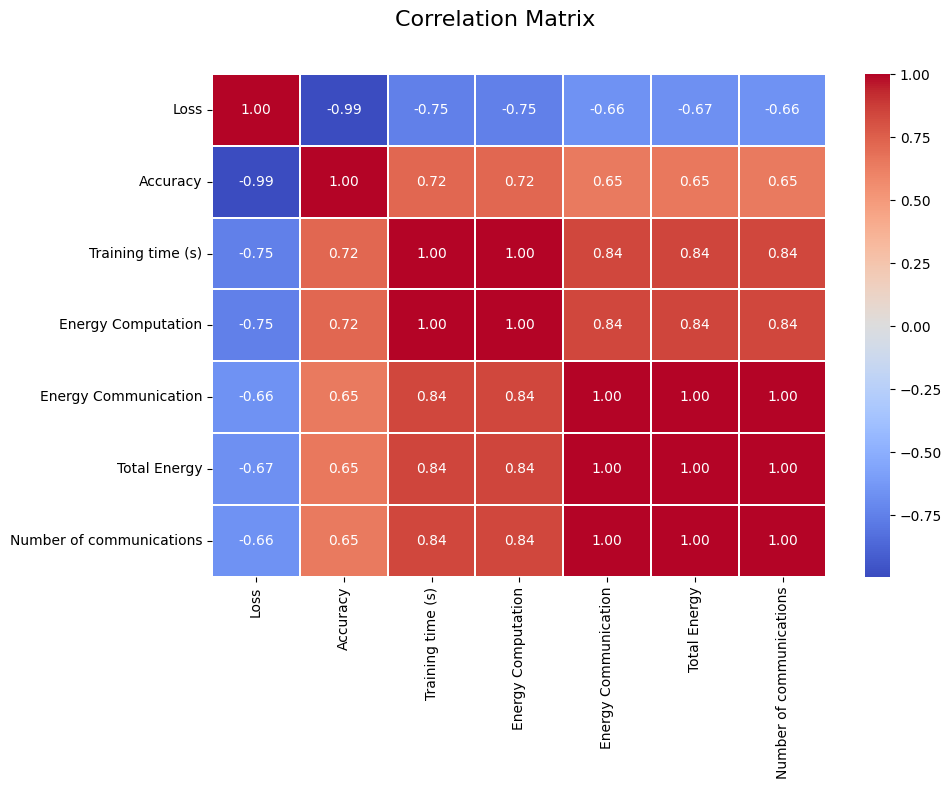

In [17]:
corr= df.corr()
fig, ax = plt.subplots(figsize=(10, 8))
fig.suptitle('Correlation Matrix', fontsize=16)
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.2)

fig.tight_layout()              # <-- sistema spazi
fig.subplots_adjust(top=0.9)    # <-- lascia spazio al titolo
fig.savefig("img/correlation_matrix.png", bbox_inches="tight")  # <-- evita il taglio



In [35]:
df.iloc[-25:].sum()


Loss                            0.035449
Accuracy                       17.783300
Training time (s)             732.444160
Energy Computation             73.244416
Energy Communication         1798.642594
Total Energy                 1871.887010
Number of communications    29195.000000
dtype: float64

# Evaluate Model

In [7]:
from reinforcement import OptHierFLEnv
env = OptHierFLEnv(env_name="HierFL-v0",global_rounds=3 ,max_round=1)
model=PPO.load("../ppo_HierFL.zip", env=env)
avg_reward,std_reward=evaluate_policy(model, env, n_eval_episodes=1, render=True)
print(avg_reward)
print(std_reward)

(ClientAppActor pid=1551134) Number of iteration: 39
(ClientAppActor pid=1551134) local update energy consumed: 0.038338559999999994
(ClientAppActor pid=1551134) train time: 0.3833856000000001
(ClientAppActor pid=1551134) Local update size: 0.248024 MB (1984192 bits)


INFO :      aggregate_fit: received 4 results and 0 failures
INFO :      configure_evaluate: strategy sampled 4 clients (out of 6)


Paramters Aggregated : numpy.ndarray
Total samples: 268
[{'droneId': 25, 'consumedEnergyComputation': 0.038338559999999994, 'trainTimeComputation': 0.3833856000000001, 'consumedEnergyCommunication': 0.1749111425, 'num_communications': 1}, {'droneId': 24, 'consumedEnergyComputation': 0.038338559999999994, 'trainTimeComputation': 0.3833856000000001, 'consumedEnergyCommunication': 0.1749111425, 'num_communications': 1}, {'droneId': 28, 'consumedEnergyComputation': 0.038338559999999994, 'trainTimeComputation': 0.3833856000000001, 'consumedEnergyCommunication': 0.1749111425, 'num_communications': 1}, {'droneId': 26, 'consumedEnergyComputation': 0.038338559999999994, 'trainTimeComputation': 0.3833856000000001, 'consumedEnergyCommunication': 0.1749111425, 'num_communications': 1}]
DroneId: 25 - consumedEnergyComputation: 0.038338559999999994
DroneId: 24 - consumedEnergyComputation: 0.038338559999999994
DroneId: 28 - consumedEnergyComputation: 0.038338559999999994
DroneId: 26 - consumedEnergyC

INFO :      aggregate_evaluate: received 4 results and 0 failures
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 4 clients (out of 6)


fit_config function called on configure_fit


...

INFO :      aggregate_fit: received 4 results and 0 failures
INFO :      configure_evaluate: strategy sampled 4 clients (out of 6)


Paramters Aggregated : numpy.ndarray
Total samples: 268
[{'droneId': 27, 'consumedEnergyComputation': 0.038338559999999994, 'trainTimeComputation': 0.3833856000000001, 'consumedEnergyCommunication': 0.1749111425, 'num_communications': 1}, {'droneId': 28, 'consumedEnergyComputation': 0.038338559999999994, 'trainTimeComputation': 0.3833856000000001, 'consumedEnergyCommunication': 0.1749111425, 'num_communications': 1}, {'droneId': 29, 'consumedEnergyComputation': 0.038338559999999994, 'trainTimeComputation': 0.3833856000000001, 'consumedEnergyCommunication': 0.1749111425, 'num_communications': 1}, {'droneId': 25, 'consumedEnergyComputation': 0.038338559999999994, 'trainTimeComputation': 0.3833856000000001, 'consumedEnergyCommunication': 0.1749111425, 'num_communications': 1}]
DroneId: 25 - consumedEnergyComputation: 0.11501567999999998
DroneId: 24 - consumedEnergyComputation: 0.038338559999999994
DroneId: 28 - consumedEnergyComputation: 0.11501567999999998
DroneId: 26 - consumedEnergyCom

INFO :      aggregate_evaluate: received 4 results and 0 failures
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 3 round(s) in 13.25s
INFO :      	History (loss, distributed):
INFO :      		round 1: 0.0985989503696293
INFO :      		round 2: 0.09265593693641845
INFO :      		round 3: 0.09021734236600157
INFO :      


SIMULATION CLUSTER 5 FINISHED
RESULTS
--- RL ENV STEP 1: Finished. Accuracy: 0.9511, Reward: 0.1315 ---
0.1314641833305359
0.0


/home/domenico/Desktop/bioai/lib/python3.10/site-packages/stable_baselines3/common/vec_env/base_vec_env.py:259: UserWarning: You tried to call render() but no `render_mode` was passed to the env constructor.
  warnings.warn("You tried to call render() but no `render_mode` was passed to the env constructor.")


# Analisi normalizzazione


In [20]:
res=pd.read_csv("reuslts_trained.csv")
res.head(2)

,k1,k2,score,step,accuracy_tot,training_time_tot,computation_energy_tot,communication_energy_tot,total_energy_tot,communications_tot,accuracy_avg,training_time_avg,computation_energy_avg,communication_energy_avg,total_energy_avg,communications_avg
0,8,4,-1.506306,1,0.429,35.861299,3.586130,79.759481,83.345611,456,0.143,11.953766,1.195377,26.586494,27.781870,152.0
1,16,5,0.369375,2,0.771,89.653248,8.965325,99.699351,108.664676,570,0.257,29.884416,2.988442,33.233117,36.221559,190.0


In [ ]:
res["nomalized accuracy"]=res["accuracy_tot"].apply(lambda x: (x-0)/(3-0))
res["nomalized time"]=res["training_time_tot"].apply(lambda x: (x-0)/(5-0))
res["nomalized total energy"]=res["total_energy_tot"].apply(lambda x: (x-0)/(5000-0))

In [26]:
res.head(15)

,k1,k2,score,step,accuracy_tot,training_time_tot,computation_energy_tot,communication_energy_tot,total_energy_tot,communications_tot,accuracy_avg,training_time_avg,computation_energy_avg,communication_energy_avg,total_energy_avg,communications_avg,nomalized accuracy,nomalized time,nomalized total energy
0,8,4,-1.506306,1,0.4290,35.861299,3.586130,79.759481,83.345611,456,0.143000,11.953766,1.195377,26.586494,27.781870,152.0,0.143000,0.017931,0.016669
1,16,5,0.369375,2,0.7710,89.653248,8.965325,99.699351,108.664676,570,0.257000,29.884416,2.988442,33.233117,36.221559,190.0,0.257000,0.044827,0.021733
2,25,4,-0.086669,3,0.9039,112.066560,11.206656,79.759481,90.966137,456,0.301300,37.355520,3.735552,26.586494,30.322046,152.0,0.301300,0.056033,0.018193
3,19,2,-0.831428,4,0.4713,42.585293,4.258529,39.879740,44.138270,228,0.157100,14.195098,1.419510,13.293247,14.712757,76.0,0.157100,0.021293,0.008828
4,16,2,-0.544575,5,0.5369,35.861299,3.586130,39.879740,43.465870,228,0.178967,11.953766,1.195377,13.293247,14.488623,76.0,0.178967,0.017931,0.008693
5,6,7,-1.287316,1,0.4189,47.067955,4.706796,139.579092,144.285887,798,0.139633,15.689318,1.568932,46.526364,48.095296,266.0,0.139633,0.023534,0.028857
6,19,9,0.229164,2,1.0916,191.633818,19.163382,179.458832,198.622214,1026,0.363867,63.877939,6.387794,59.819611,66.207405,342.0,0.363867,0.095817,0.039724
7,24,10,0.177844,3,1.2487,268.959744,26.895974,199.398702,226.294677,1140,0.416233,89.653248,8.965325,66.466234,75.431559,380.0,0.416233,0.134480,0.045259
8,10,6,-0.471126,4,0.6603,67.239936,6.723994,119.639221,126.363215,684,0.220100,22.413312,2.241331,39.879740,42.121072,228.0,0.220100,0.033620,0.025273
9,18,6,0.275157,5,0.8396,121.031885,12.103188,119.639221,131.742410,684,0.279867,40.343962,4.034396,39.879740,43.914137,228.0,0.279867,0.060516,0.026348
